# Book Recommendation System
Data Mining Lab Assignment

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from zipfile import ZipFile
from urllib.request import urlretrieve
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors
from collections import defaultdict
from IPython.display import display

for folder in ['raw', 'bronze', 'silver', 'gold']:
    Path(folder).mkdir(exist_ok=True)

## 1. Bronze layer
Load the CSV files and save them as Parquet without cleaning.

In [3]:
from google.colab import files
from pathlib import Path
from zipfile import ZipFile

zip_path = Path('book-crossings.zip')

Path('raw').mkdir(exist_ok=True)
Path('bronze').mkdir(exist_ok=True)

if not list(Path('raw').rglob('*.csv')):
    if not zip_path.exists():
        uploaded = files.upload()
        zip_path = Path(next(iter(uploaded)))

    with ZipFile(zip_path) as z:
        z.extractall('raw')

csv_files = list(Path('raw').rglob('*.csv'))

files = {
    'users': next(p for p in csv_files if 'users' in p.name.lower()),
    'ratings': next(p for p in csv_files if 'ratings' in p.name.lower()),
    'books': next(p for p in csv_files if 'books' in p.name.lower() and 'ratings' not in p.name.lower())
}

stamp = pd.Timestamp.now(tz='UTC')

for name, path in files.items():
    options = dict(sep=';', encoding='latin-1', dtype=str,
                   keep_default_na=False, na_values=['NULL', ''])

    try:
        df = pd.read_csv(path, **options)

    except pd.errors.ParserError:
        rejected = []

        def keep_rejected(fields):
            rejected.append(fields)
            return None

        df = pd.read_csv(path, engine='python',
                         on_bad_lines=keep_rejected, **options)

        pd.DataFrame({'fields': [repr(row) for row in rejected]}).to_parquet(
            f'bronze/{name}_parse_errors.parquet', index=False)

        print(name, 'unparseable records:', len(rejected))

    df['ingestion_timestamp'] = stamp
    df.to_parquet(f'bronze/{name}.parquet', index=False)
    print(name, df.shape)

Saving book-crossings (3).zip to book-crossings (3).zip
users (278858, 4)
ratings (1149780, 4)
books unparseable records: 0
books (270491, 9)


## 2. EDA

In [5]:
users = pd.read_parquet('bronze/users.parquet')
books = pd.read_parquet('bronze/books.parquet')
ratings = pd.read_parquet('bronze/ratings.parquet')

for name, df in [('Users', users), ('Books', books), ('Ratings', ratings)]:
    print(name, df.shape)
    display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum()}))

Users (278858, 4)


,dtype,missing
User-ID,object,0
Location,object,0
Age,object,110762
ingestion_timestamp,"datetime64[us, UTC]",0


Books (270491, 9)


,dtype,missing
ISBN,object,0
Book-Title,object,0
Book-Author,object,0
Year-Of-Publication,object,0
Publisher,object,0
Image-URL-S,object,0
Image-URL-M,object,0
Image-URL-L,object,0
ingestion_timestamp,"datetime64[us, UTC]",0


Ratings (1149780, 4)


,dtype,missing
User-ID,object,0
ISBN,object,0
Book-Rating,object,0
ingestion_timestamp,"datetime64[us, UTC]",0


The tables have missing values, especially in Age. I will fill missing ages and convert numeric columns in Silver.

Zero ratings: 716109


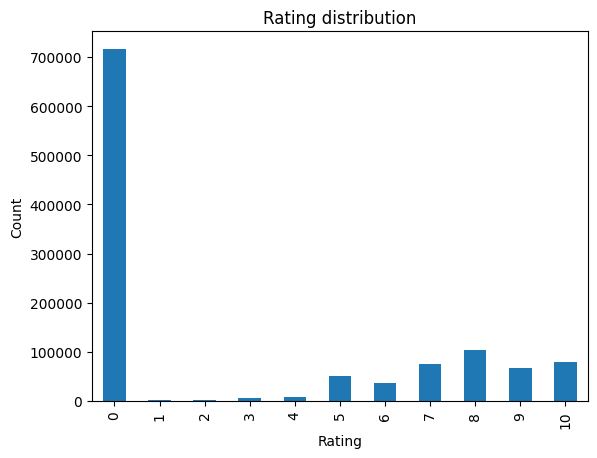

In [6]:
rating_values = pd.to_numeric(ratings['Book-Rating'], errors='coerce')
print('Zero ratings:', (rating_values == 0).sum())
rating_values.value_counts().sort_index().plot.bar(title='Rating distribution')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

Ratings of 0 are not actual ratings, so I will remove them.

Invalid ages: 1248
Invalid years: 4622


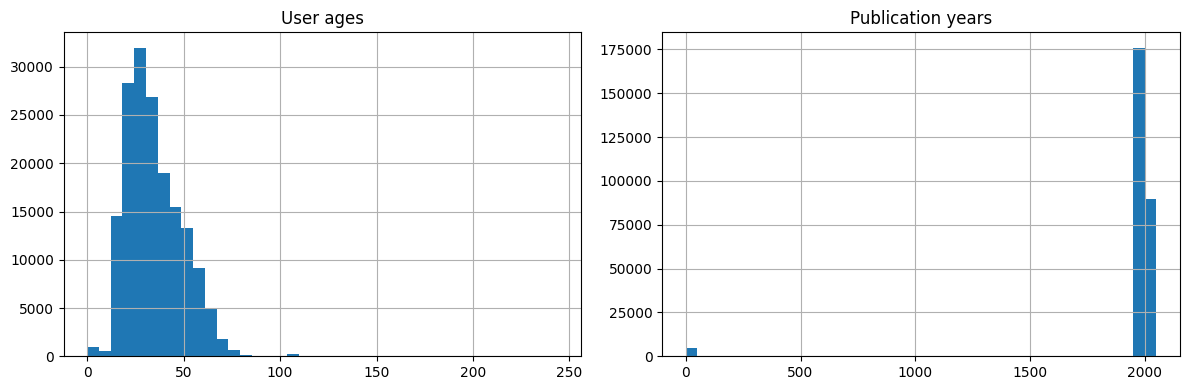

In [7]:
ages = pd.to_numeric(users['Age'], errors='coerce')
years = pd.to_numeric(books['Year-Of-Publication'], errors='coerce')
current_year = pd.Timestamp.now().year
print('Invalid ages:', ((ages < 5) | (ages > 100)).sum())
print('Invalid years:', ((years <= 0) | (years > current_year)).sum())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ages.dropna().hist(ax=ax[0], bins=40)
ax[0].set_title('User ages')
years.dropna().hist(ax=ax[1], bins=40)
ax[1].set_title('Publication years')
plt.tight_layout()
plt.show()

Some ages and publication years are invalid. I will fix the ages using the median and replace invalid years with null.

,ratings per user,ratings per book
count,105283.000000,340556.000000
mean,10.920851,3.376185
std,90.562825,12.436252
min,1.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,4.000000,2.000000
max,13602.000000,2502.000000


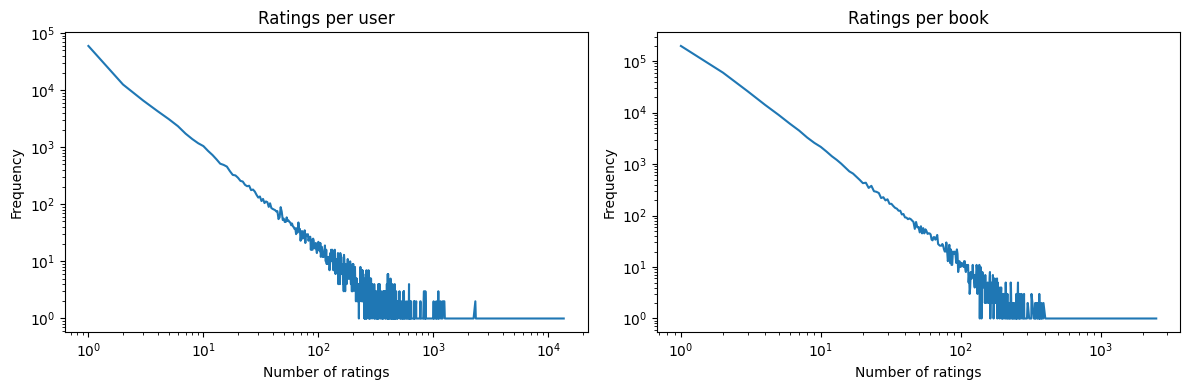

Observed pairs: 0.001364%
Empty pairs (sparsity): 99.998636%


In [8]:
user_counts = ratings.groupby('User-ID').size()
book_counts = ratings.groupby('ISBN').size()
display(pd.DataFrame({'ratings per user': user_counts.describe(),
                      'ratings per book': book_counts.describe()}))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for counts, axis, title in [(user_counts, ax[0], 'Ratings per user'),
                            (book_counts, ax[1], 'Ratings per book')]:
    counts.value_counts().sort_index().plot(ax=axis, loglog=True)
    axis.set_title(title)
    axis.set_xlabel('Number of ratings')
    axis.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

valid_pairs = ratings.loc[ratings['User-ID'].isin(users['User-ID']) &
                          ratings['ISBN'].isin(books['ISBN']), ['User-ID', 'ISBN']]
possible = users['User-ID'].nunique() * books['ISBN'].nunique()
density = len(valid_pairs.drop_duplicates()) / possible * 100
print(f'Observed pairs: {density:.6f}%')
print(f'Empty pairs (sparsity): {100-density:.6f}%')

Most users and books have few ratings, so I chose a minimum of 10 ratings for both.

Most user-book pairs are empty, so I will use a sparse matrix.

## 3. Silver layer

In [9]:
users = users.drop_duplicates().copy()
books = books.drop_duplicates().copy()
ratings = ratings.drop_duplicates().copy()

users = users.rename(columns={'User-ID': 'user_id', 'Location': 'location', 'Age': 'age'})
books = books.rename(columns={'ISBN': 'isbn', 'Book-Title': 'title',
                              'Book-Author': 'author', 'Year-Of-Publication': 'year',
                              'Publisher': 'publisher'})
ratings = ratings.rename(columns={'User-ID': 'user_id', 'ISBN': 'isbn', 'Book-Rating': 'rating'})

for df in [users, ratings]:
    df['user_id'] = pd.to_numeric(df['user_id'], errors='coerce').astype('Int64')
    df.dropna(subset=['user_id'], inplace=True)
for df in [books, ratings]:
    df['isbn'] = df['isbn'].str.strip().str.upper()
    df.dropna(subset=['isbn'], inplace=True)
    df.drop(df[df['isbn'] == ''].index, inplace=True)

users['age'] = pd.to_numeric(users['age'], errors='coerce')
users['age'] = users['age'].where(users['age'].between(5, 100))
users['age'] = users['age'].fillna(users['age'].median())
location = users['location'].str.rsplit(',', n=2, expand=True).reindex(columns=range(3))
location.columns = ['city', 'state', 'country']
for col in location.columns:
    users[col] = location[col].str.strip().str.lower().replace('', pd.NA)
users = users.drop(columns='location')

books['year'] = pd.to_numeric(books['year'], errors='coerce')
books['year'] = books['year'].where(books['year'].between(1, current_year)).astype('Int64')
for col in ['title', 'author', 'publisher']:
    books[col] = books[col].str.strip().str.replace(r'\s+', ' ', regex=True).str.lower()
books = books.drop(columns=[c for c in books if c.startswith('Image-URL')])
books = books.dropna(subset=['title'])
books = books[books['title'] != '']
users = users.drop_duplicates('user_id')
books = books.drop_duplicates('isbn')

ratings['rating'] = pd.to_numeric(ratings['rating'], errors='coerce')
ratings = ratings[ratings['rating'].between(1, 10)]
ratings = ratings[ratings['user_id'].isin(users['user_id']) & ratings['isbn'].isin(books['isbn'])]
ratings = ratings.groupby(['user_id', 'isbn'], as_index=False)['rating'].mean()
print('Valid explicit ratings:', len(ratings))

Valid explicit ratings: 382828


In [10]:
min_ratings = 10
print('Users meeting threshold:', (ratings.groupby('user_id').size() >= min_ratings).sum())
print('Books meeting threshold:', (ratings.groupby('isbn').size() >= min_ratings).sum())

while True:
    before = len(ratings)
    active_users = ratings['user_id'].value_counts()
    popular_books = ratings['isbn'].value_counts()
    ratings = ratings[ratings['user_id'].isin(active_users[active_users >= min_ratings].index) &
                      ratings['isbn'].isin(popular_books[popular_books >= min_ratings].index)]
    if len(ratings) == before:
        break

users = users[users['user_id'].isin(ratings['user_id'])]
books = books[books['isbn'].isin(ratings['isbn'])]
assert not ratings.empty, 'No ratings left; lower the threshold and rerun Silver.'
for name, df in [('users', users), ('books', books), ('ratings', ratings)]:
    df.to_parquet(f'silver/{name}.parquet', index=False)
    print(name, df.shape)

Users meeting threshold: 6570
Books meeting threshold: 5438
users (1813, 6)
books (2022, 6)
ratings (41251, 3)


## 4. Gold layer
Create the rating matrix, book lookup and rating statistics.

In [11]:
ratings = pd.read_parquet('silver/ratings.parquet')
books = pd.read_parquet('silver/books.parquet')
user_ids = pd.Index(sorted(ratings['user_id'].unique()))
book_ids = pd.Index(sorted(ratings['isbn'].unique()))

matrix = csr_matrix((ratings['rating'].astype('float32'),
                    (user_ids.get_indexer(ratings['user_id']),
                     book_ids.get_indexer(ratings['isbn']))),
                    shape=(len(user_ids), len(book_ids)))
save_npz('gold/user_book_matrix.npz', matrix)
pd.DataFrame({'user_id': user_ids}).to_parquet('gold/user_index.parquet', index=False)
lookup = books.set_index('isbn').loc[book_ids, ['title', 'author']].reset_index()
lookup.to_parquet('gold/book_lookup.parquet', index=False)

for col, name in [('user_id', 'user_stats'), ('isbn', 'book_stats')]:
    stats = ratings.groupby(col)['rating'].agg(avg_rating='mean', rating_count='size').reset_index()
    stats.to_parquet(f'gold/{name}.parquet', index=False)
    display(stats.head())
print('Matrix shape:', matrix.shape)
print('Non-zero entries:', matrix.nnz)

,user_id,avg_rating,rating_count
0,243,7.769231,13
1,254,8.450000,20
2,638,9.454545,22
3,805,8.400000,10
4,882,8.235294,17


,isbn,avg_rating,rating_count
0,0020199600,8.090909,11
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.900000,10
4,0060002050,7.545455,11


Matrix shape: (1813, 2022)
Non-zero entries: 41251


## 5. Item-based collaborative filtering

In [12]:
matrix = load_npz('gold/user_book_matrix.npz')
book_matrix = matrix.T.tocsr()
lookup = pd.read_parquet('gold/book_lookup.parquet')
user_ids = pd.read_parquet('gold/user_index.parquet')['user_id']
user_index = {uid: i for i, uid in enumerate(user_ids)}
model = NearestNeighbors(metric='cosine', algorithm='brute')
model.fit(book_matrix)

def neighbors(book_idx, n=10):
    distances, indices = model.kneighbors(book_matrix[book_idx],
                                         n_neighbors=min(n + 1, len(lookup)))
    return [(int(i), float(1 - d)) for i, d in zip(indices[0], distances[0])
            if i != book_idx and d < 1][:n]

def similar_books(title, n=10):
    matches = lookup.index[lookup['title'] == title.strip().lower()]
    if len(matches) == 0:
        return pd.DataFrame(columns=['title', 'author', 'similarity'])
    items = neighbors(matches[0], n)
    result = lookup.iloc[[i for i, _ in items]][['title', 'author']].copy()
    result['similarity'] = [round(s, 4) for _, s in items]
    return result.reset_index(drop=True)

def recommend(user_id, n=10):
    if user_id not in user_index:
        return []
    row = matrix.getrow(user_index[user_id])
    seen = set(row.indices)
    liked = [(i, r) for i, r in zip(row.indices, row.data) if r >= 8]
    if not liked:
        return []
    seen_titles = set(lookup.iloc[list(seen)]['title'])
    scores = defaultdict(float)
    for i, rating in liked:
        for j, similarity in neighbors(i, 50):
            if j not in seen and lookup.iloc[j]['title'] not in seen_titles:
                scores[j] += similarity * float(rating) / 10
    ranked = sorted(scores, key=lambda j: (-scores[j], j))
    titles = list(dict.fromkeys(lookup.iloc[j]['title'] for j in ranked))
    return titles[:n]

I considered ratings of 8 and above as liked books. Recommendations are based on similar books that the user has not rated yet.

## 6. Testing

In [14]:
example = lookup.iloc[0]['title']
print('Similar books for:', example)
display(similar_books(example))

liked_counts = ratings[ratings['rating'] >= 8].groupby('user_id').size()
demo_users = []
for uid in liked_counts.sort_values(ascending=False).index:
    if len(recommend(uid)) == 10:
        demo_users.append(uid)
    if len(demo_users) == 3:
        break
assert len(demo_users) == 3, 'Could not find three users with ten recommendations.'

for uid in demo_users:
    row = matrix.getrow(user_index[uid])
    liked = sorted([(lookup.iloc[i]['title'], float(r)) for i, r in zip(row.indices, row.data)
                    if r >= 8], key=lambda x: -x[1])
    recs = recommend(uid)
    liked_text = [f'{title} ({r:g}/10)' for title, r in liked]
    print('User:', uid, '| Highly rated books:', len(liked))
    display(pd.DataFrame({'Highly rated books (up to 10)': pd.Series(liked_text[:10]),
                          'Recommendations': pd.Series(recs)}))
    assert len(recs) == len(set(recs)) == 10
    assert not set(recs) & set(lookup.iloc[row.indices]['title'])

assert matrix.nnz == len(ratings)
assert ratings.groupby('user_id').size().min() >= min_ratings
assert ratings.groupby('isbn').size().min() >= min_ratings
assert recommend(-1) == []
print('All sanity checks passed.')

Similar books for: great gatsby (reissue)


,title,author,similarity
0,name of the rose-nla,umberto eco,0.2844
1,the cereal murders,diane mott davidson,0.2081
2,"the subtle knife (his dark materials, book 2)",philip pullman,0.2000
3,the little prince,antoine de saint-exupã©ry,0.1580
4,the outsiders,s. e. hinton,0.1558
5,devil's waltz (alex delaware novels (paperback)),jonathan kellerman,0.1443
6,fast food nation: the dark side of the all-ame...,eric schlosser,0.1410
7,the book borrower: a novel,alice mattison,0.1388
8,a widow for one year,john irving,0.1347
9,nobody's baby but mine,susan elizabeth phillips,0.1313


User: 11676 | Highly rated books: 604


,Highly rated books (up to 10),Recommendations
0,the poisonwood bible (10/10),"night shield (intimate moments, 1027)"
1,daughter of fortune : a novel (oprah's book cl...,public secrets
2,prodigal summer (10/10),birthright
3,i know this much is true (oprah's book club) (...,palomino
4,the poisonwood bible (10/10),night tales
5,to kill a mockingbird (10/10),tears of the moon (irish trilogy)
6,fast food nation: the dark side of the all-ame...,stanislaski brothers (silhouette promo)
7,the professor and the madman: a tale of murder...,perfect
8,courting trouble (10/10),conspiracy in death
9,the alchemist: a fable about following your dr...,macgregor grooms (macgregors)


User: 104636 | Highly rated books: 170


,Highly rated books (up to 10),Recommendations
0,where the sidewalk ends : poems and drawings (...,the gift
1,little house on the prairie (10/10),the face of fear
2,charlotte's web (trophy newbery) (10/10),if there be thorns (dollanganger)
3,bridge to terabithia (10/10),garden of shadows (dollanger saga (paperback))
4,"the lion, the witch, and the wardrobe (the chr...",five days in paris
5,eyes of a child (10/10),the anastasia syndrome
6,talk before sleep (10/10),midnight bayou
7,harry potter and the chamber of secrets (book ...,seeds of yesterday (dollanganger)
8,harry potter and the prisoner of azkaban (book...,fallen hearts
9,harry potter and the goblet of fire (book 4) (...,the endearment


User: 153662 | Highly rated books: 163


,Highly rated books (up to 10),Recommendations
0,the divine secrets of the ya-ya sisterhood: a ...,born in shame
1,the perfect storm : a true story of men agains...,night tales
2,the secret garden (10/10),the macgregors: serena - caine (the macgregors)
3,slammerkin (10/10),loyalty in death
4,i capture the castle (10/10),considering kate (the stanislaskis) (silhouett...
5,2010: odyssey two (10/10),the villa
6,the fellowship of the ring (the lord of the ri...,paradise
7,fahrenheit 451 (10/10),ceremony in death (eve dallas mysteries (paper...
8,the killer angels (10/10),the macgregors: alan - grant (the macgregors)
9,pope joan (ballantine reader's circle) (10/10),when the storm breaks


All sanity checks passed.
